Upload your input image:


Saving 1.jpg to 1 (1).jpg
Image uploaded successfully!
Image size: (1366, 2048)

Optimizing contrast and sharpness...
Iteration 1/20 | Best Fitness = 24.3521
Iteration 2/20 | Best Fitness = 24.3521
Iteration 3/20 | Best Fitness = 24.3521
Iteration 4/20 | Best Fitness = 24.5370
Iteration 5/20 | Best Fitness = 24.5370
Iteration 6/20 | Best Fitness = 24.5370
Iteration 7/20 | Best Fitness = 24.5370
Iteration 8/20 | Best Fitness = 24.5370
Iteration 9/20 | Best Fitness = 24.5370
Iteration 10/20 | Best Fitness = 24.5370
Iteration 11/20 | Best Fitness = 24.5370
Iteration 12/20 | Best Fitness = 24.5370
Iteration 13/20 | Best Fitness = 24.5370
Iteration 14/20 | Best Fitness = 24.5370
Iteration 15/20 | Best Fitness = 24.5370
Iteration 16/20 | Best Fitness = 24.5370
Iteration 17/20 | Best Fitness = 24.5370
Iteration 18/20 | Best Fitness = 24.5370
Iteration 19/20 | Best Fitness = 24.5370
Iteration 20/20 | Best Fitness = 24.5370

Optimizing brightness...
Iteration 1/20 | Best Fitness = 0.0001
Iterat

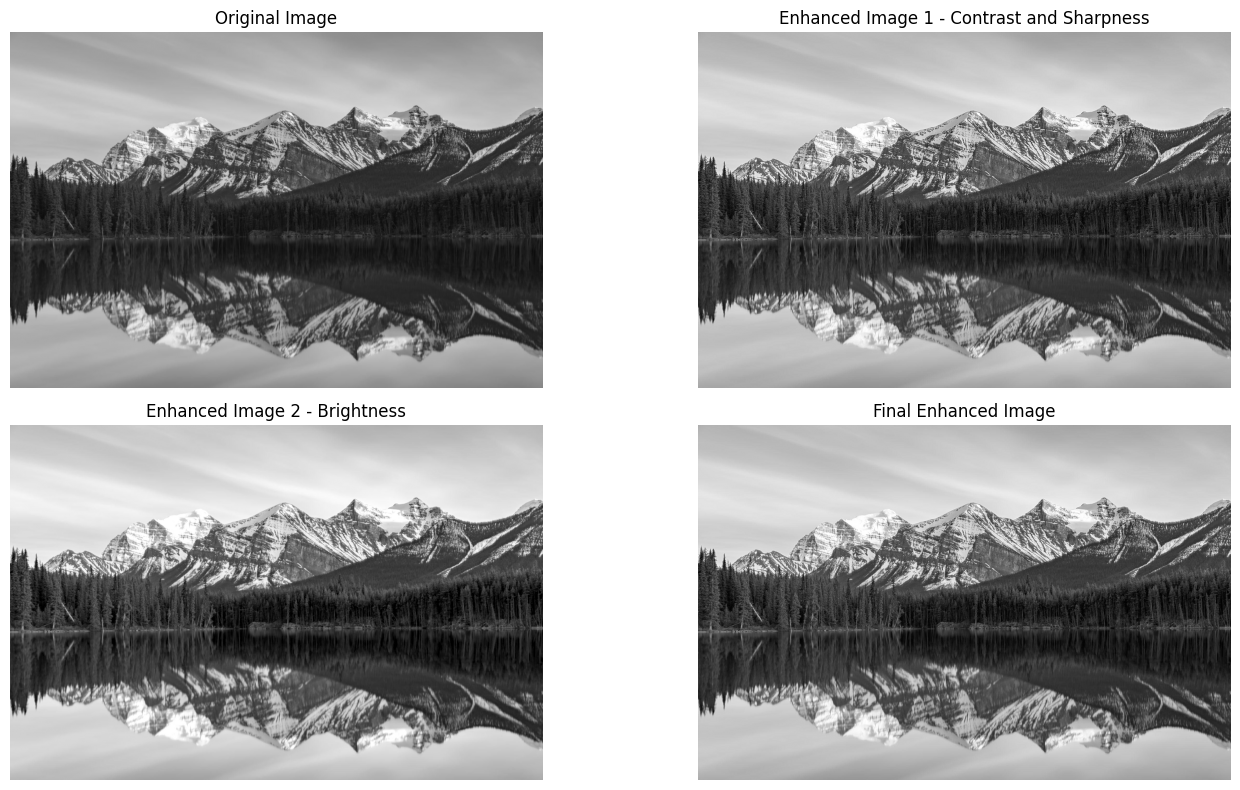

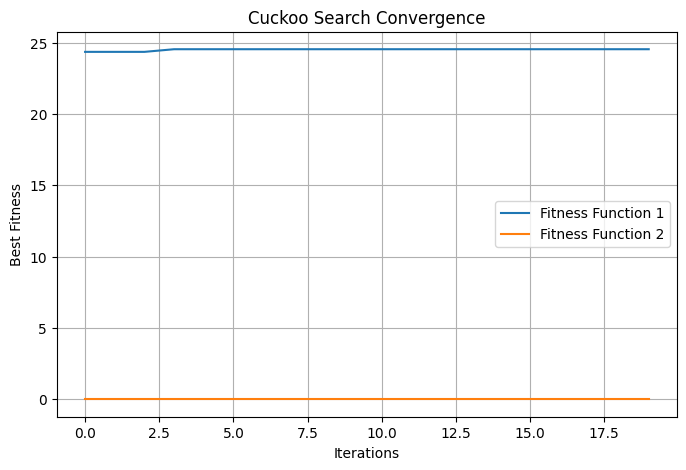


========== IMAGE ENHANCEMENT RESULTS ==========
Contrast Improvement Index (CII): 1.1258
Brightness Improvement (BI):      0.0770
Image Sharpness:                  1759.7902
Image Entropy:                    7.6188

Best Parameters - Fitness 1: [1.38601865 0.21064976 1.84610485 0.29354488]
Best Parameters - Fitness 2: [0.15017145 0.85888736 2.14359907 0.23213327]

Final enhanced image saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:

# ============================================================
# CUCKOO SEARCH BASED IMAGE ENHANCEMENT
# Research-inspired implementation
# ============================================================

!pip -q install opencv-python-headless scipy scikit-image matplotlib

import cv2
import math
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from scipy.ndimage import uniform_filter
from scipy.special import expit
from skimage.measure import shannon_entropy

# -------------------- 1. UPLOAD IMAGE ------------------------

print("Upload your input image:")
uploaded = files.upload()

filename = next(iter(uploaded))

img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Could not read the uploaded image.")

img = img.astype(np.float32) / 255.0

print("Image uploaded successfully!")
print("Image size:", img.shape)


# -------------------- 2. IMAGE TRANSFORMATION ----------------

def transform_image(image, params):

    a, b, c, d = params

    mean = uniform_filter(image, size=3)
    mean_sq = uniform_filter(image ** 2, size=3)

    local_std = np.sqrt(np.maximum(mean_sq - mean ** 2, 0))

    enhanced = c * image - a * mean + b * local_std

    low = np.percentile(enhanced, 1)
    high = np.percentile(enhanced, 99)

    enhanced = (enhanced - low) / (high - low + 1e-8)
    enhanced = np.clip(enhanced, 0, 1)

    enhanced = np.power(enhanced, 0.5 + d)

    return np.clip(enhanced, 0, 1)


# -------------------- 3. FITNESS FUNCTION 1 ------------------

def fitness1(image):

    image_uint8 = (image * 255).astype(np.uint8)

    sobel_x = cv2.Sobel(
        image_uint8, cv2.CV_64F, 1, 0, ksize=3
    )

    sobel_y = cv2.Sobel(
        image_uint8, cv2.CV_64F, 0, 1, ksize=3
    )

    sharpness = np.mean(
        np.sqrt(sobel_x ** 2 + sobel_y ** 2)
    )

    edges = cv2.Canny(image_uint8, 100, 200)
    edge_count = np.sum(edges > 0)

    entropy = shannon_entropy(image_uint8)

    score = (
        np.log1p(sharpness)
        + np.log1p(edge_count)
        + entropy
    )

    return float(score)


# -------------------- 4. FITNESS FUNCTION 2 ------------------

def fitness2(image):

    mean_intensity = np.mean(image)

    histogram, _ = np.histogram(
        image, bins=256, range=(0, 1)
    )

    histogram_std = np.std(histogram)

    score = mean_intensity / (histogram_std + 1e-8)

    return float(score)


# -------------------- 5. LEVY FLIGHT -------------------------

def levy_flight(beta=1.5):

    sigma = (
        math.gamma(1 + beta)
        * math.sin(math.pi * beta / 2)
        /
        (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (abs(v) ** (1 / beta) + 1e-8)


# -------------------- 6. CUCKOO SEARCH -----------------------

LOWER = np.array([0.0, 0.0, 0.5, 0.0])
UPPER = np.array([1.5, 1.5, 2.5, 1.0])

NESTS = 15
ITERATIONS = 20
PA = 0.25
ALPHA = 0.01

def cuckoo_search(objective):

    population = np.random.uniform(
        LOWER, UPPER, (NESTS, 4)
    )

    scores = np.array([
        objective(transform_image(img, nest))
        for nest in population
    ])

    best_index = np.argmax(scores)
    best_nest = population[best_index].copy()
    best_score = scores[best_index]

    history = []

    for iteration in range(ITERATIONS):

        # Generate new solutions using Levy flights
        for i in range(NESTS):

            step = np.array([
                levy_flight() for _ in range(4)
            ])

            new_nest = (
                population[i]
                + ALPHA * step * (population[i] - best_nest)
            )

            new_nest = np.clip(new_nest, LOWER, UPPER)

            new_score = objective(
                transform_image(img, new_nest)
            )

            if new_score > scores[i]:
                population[i] = new_nest
                scores[i] = new_score

            if new_score > best_score:
                best_score = new_score
                best_nest = new_nest.copy()

        # Abandon some nests and create new solutions
        abandon = np.random.rand(NESTS) < PA

        for i in range(NESTS):

            if abandon[i]:

                new_nest = np.random.uniform(
                    LOWER, UPPER, 4
                )

                new_score = objective(
                    transform_image(img, new_nest)
                )

                if new_score > scores[i]:
                    population[i] = new_nest
                    scores[i] = new_score

                if new_score > best_score:
                    best_score = new_score
                    best_nest = new_nest.copy()

        history.append(best_score)

        print(
            f"Iteration {iteration + 1}/{ITERATIONS} "
            f"| Best Fitness = {best_score:.4f}"
        )

    return best_nest, history


# -------------------- 7. OPTIMIZE BOTH OBJECTIVES ------------

print("\nOptimizing contrast and sharpness...")

best_params1, history1 = cuckoo_search(fitness1)

print("\nOptimizing brightness...")

best_params2, history2 = cuckoo_search(fitness2)


# -------------------- 8. GENERATE ENHANCED IMAGES ------------

image1 = transform_image(img, best_params1)
image2 = transform_image(img, best_params2)


# -------------------- 9. IMAGE FUSION ------------------------

A = (image1 + image2) / 2.0

W = expit(A)

final_image = W * image1 + (1 - W) * image2

final_image = np.clip(final_image, 0, 1)


# -------------------- 10. IMAGE QUALITY METRICS --------------

def calculate_metrics(original, enhanced):

    original_mean = np.mean(original)
    enhanced_mean = np.mean(enhanced)

    original_contrast = np.std(original)
    enhanced_contrast = np.std(enhanced)

    CII = enhanced_contrast / (
        original_contrast + 1e-8
    )

    BI = abs(enhanced_mean - original_mean)

    sharpness = cv2.Laplacian(
        (enhanced * 255).astype(np.uint8),
        cv2.CV_64F
    ).var()

    entropy = shannon_entropy(
        (enhanced * 255).astype(np.uint8)
    )

    return CII, BI, sharpness, entropy


cii, bi, sharpness, entropy = calculate_metrics(
    img, final_image
)


# -------------------- 11. DISPLAY RESULTS --------------------

plt.figure(figsize=(15, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(image1, cmap="gray")
plt.title("Enhanced Image 1 - Contrast and Sharpness")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(image2, cmap="gray")
plt.title("Enhanced Image 2 - Brightness")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(final_image, cmap="gray")
plt.title("Final Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# -------------------- 12. CONVERGENCE GRAPH -----------------

plt.figure(figsize=(8, 5))

plt.plot(history1, label="Fitness Function 1")
plt.plot(history2, label="Fitness Function 2")

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("Cuckoo Search Convergence")
plt.legend()
plt.grid(True)
plt.show()


# -------------------- 13. PRINT METRICS ----------------------

print("\n========== IMAGE ENHANCEMENT RESULTS ==========")

print(f"Contrast Improvement Index (CII): {cii:.4f}")
print(f"Brightness Improvement (BI):      {bi:.4f}")
print(f"Image Sharpness:                  {sharpness:.4f}")
print(f"Image Entropy:                    {entropy:.4f}")

print("\nBest Parameters - Fitness 1:", best_params1)
print("Best Parameters - Fitness 2:", best_params2)


# -------------------- 14. SAVE FINAL IMAGE -------------------

output = (final_image * 255).astype(np.uint8)

cv2.imwrite("cuckoo_search_enhanced.png", output)

print("\nFinal enhanced image saved successfully!")

files.download("cuckoo_search_enhanced.png")


Upload your color image:


Saving 1.jpg to 1 (2).jpg
Color image uploaded successfully!
Image size: (1366, 2048, 3)

Optimizing High Contrast and Sharpness...
Iteration 1/20 | Best Fitness = 27.3809
Iteration 2/20 | Best Fitness = 27.3809
Iteration 3/20 | Best Fitness = 27.3809
Iteration 4/20 | Best Fitness = 27.3809
Iteration 5/20 | Best Fitness = 27.3809
Iteration 6/20 | Best Fitness = 27.6613
Iteration 7/20 | Best Fitness = 27.6613
Iteration 8/20 | Best Fitness = 27.6613
Iteration 9/20 | Best Fitness = 27.6613
Iteration 10/20 | Best Fitness = 27.6613
Iteration 11/20 | Best Fitness = 27.6613
Iteration 12/20 | Best Fitness = 27.6613
Iteration 13/20 | Best Fitness = 27.6613
Iteration 14/20 | Best Fitness = 27.6613
Iteration 15/20 | Best Fitness = 27.6613
Iteration 16/20 | Best Fitness = 27.6613
Iteration 17/20 | Best Fitness = 27.6613
Iteration 18/20 | Best Fitness = 27.6613
Iteration 19/20 | Best Fitness = 27.6613
Iteration 20/20 | Best Fitness = 27.6613

Optimizing Brightness...
Iteration 1/20 | Best Fitness =

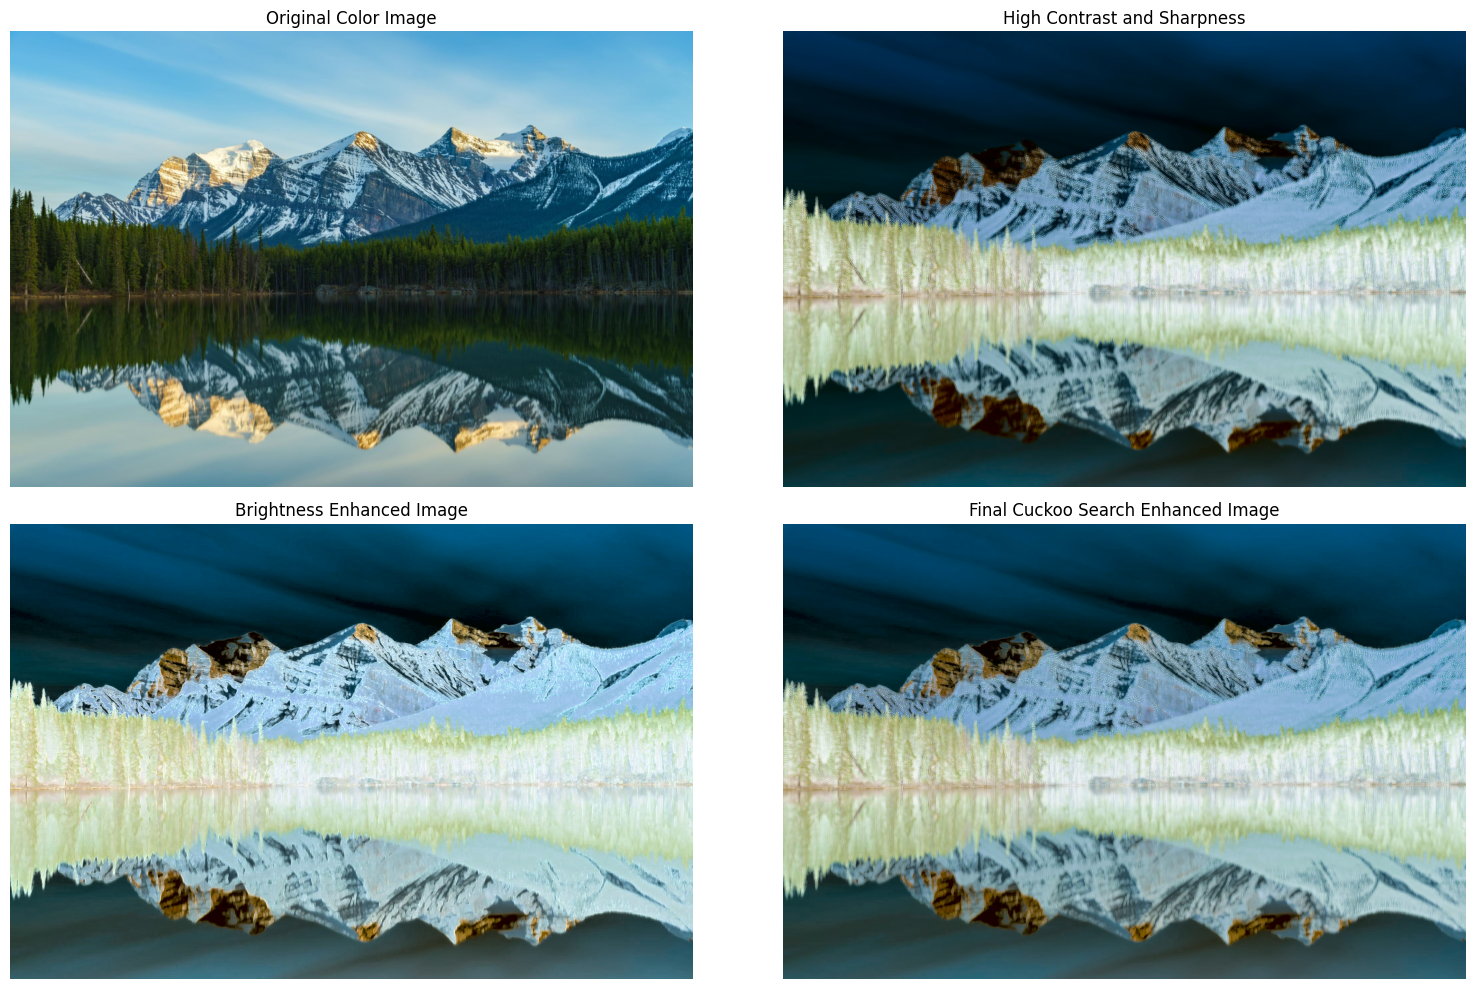

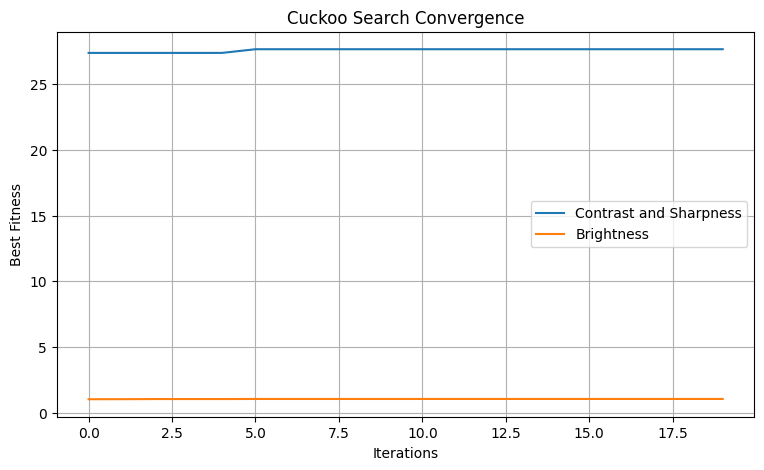


========== IMAGE ENHANCEMENT RESULTS ==========
Contrast Improvement Index: 1.0623
Brightness Improvement:     0.0221
Image Sharpness:             2058.8567
Image Entropy:               7.7418

Best Parameters - Fitness 1: [1.17941626 0.17944767 0.96239887 0.74869183]
Best Parameters - Fitness 2: [0.93747366 0.98335289 0.66179671 0.18236989]

Final color enhanced image saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

# ============================================================
# CUCKOO SEARCH BASED COLOR IMAGE ENHANCEMENT
# Two Objectives:
# 1. High Contrast and Sharpness
# 2. Brightness Enhancement
# 3. Final Image Fusion
# ============================================================

!pip -q install opencv-python-headless scipy scikit-image matplotlib

import cv2
import math
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from scipy.ndimage import uniform_filter
from scipy.special import expit
from skimage.measure import shannon_entropy

# ============================================================
# 1. UPLOAD COLOR IMAGE
# ============================================================

print("Upload your color image:")
uploaded = files.upload()

filename = next(iter(uploaded))

img_bgr = cv2.imread(filename, cv2.IMREAD_COLOR)

if img_bgr is None:
    raise ValueError("Could not read uploaded image.")

# Convert BGR to RGB
original = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Convert RGB to LAB color space
lab = cv2.cvtColor(original, cv2.COLOR_RGB2LAB)

# Extract luminance channel
L = lab[:, :, 0].astype(np.float32) / 255.0

print("Color image uploaded successfully!")
print("Image size:", original.shape)

# ============================================================
# 2. IMAGE TRANSFORMATION
# ============================================================

def transform_image(image, params):

    a, b, c, d = params

    mean = uniform_filter(image, size=3)
    mean_sq = uniform_filter(image ** 2, size=3)

    local_std = np.sqrt(
        np.maximum(mean_sq - mean ** 2, 0)
    )

    enhanced = (
        c * image
        - a * mean
        + b * local_std
    )

    low = np.percentile(enhanced, 1)
    high = np.percentile(enhanced, 99)

    enhanced = (
        enhanced - low
    ) / (high - low + 1e-8)

    enhanced = np.clip(enhanced, 0, 1)

    enhanced = np.power(
        enhanced,
        0.5 + d
    )

    return np.clip(enhanced, 0, 1)


# ============================================================
# 3. CONVERT ENHANCED LUMINANCE TO COLOR IMAGE
# ============================================================

def make_color_image(enhanced_L, original_lab):

    new_lab = original_lab.copy()

    new_lab[:, :, 0] = (
        np.clip(enhanced_L, 0, 1) * 255
    ).astype(np.uint8)

    result = cv2.cvtColor(
        new_lab,
        cv2.COLOR_LAB2RGB
    )

    return result


# ============================================================
# 4. FITNESS FUNCTION 1
# HIGH CONTRAST AND SHARPNESS
# ============================================================

def fitness1(image):

    image_uint8 = (
        np.clip(image, 0, 1) * 255
    ).astype(np.uint8)

    # Sobel edge detection
    sobel_x = cv2.Sobel(
        image_uint8,
        cv2.CV_64F,
        1, 0, ksize=3
    )

    sobel_y = cv2.Sobel(
        image_uint8,
        cv2.CV_64F,
        0, 1, ksize=3
    )

    sharpness = np.mean(
        np.sqrt(sobel_x ** 2 + sobel_y ** 2)
    )

    # Canny edge detection
    edges = cv2.Canny(
        image_uint8, 100, 200
    )

    edge_count = np.sum(edges > 0)

    # Image entropy
    entropy = shannon_entropy(image_uint8)

    # Contrast
    contrast = np.std(image)

    # Combined fitness
    score = (
        np.log1p(sharpness)
        + np.log1p(edge_count)
        + entropy
        + 10 * contrast
    )

    return float(score)


# ============================================================
# 5. FITNESS FUNCTION 2
# BRIGHTNESS ENHANCEMENT
# ============================================================

def fitness2(image):

    mean_intensity = np.mean(image)

    # Target brightness
    target = 0.55

    brightness_score = 1.0 - abs(
        mean_intensity - target
    )

    # Avoid excessive brightness changes
    contrast = np.std(image)

    score = (
        brightness_score
        + 0.2 * contrast
    )

    return float(score)


# ============================================================
# 6. LEVY FLIGHT
# ============================================================

def levy_flight(beta=1.5):

    sigma = (
        math.gamma(1 + beta)
        * math.sin(math.pi * beta / 2)
        /
        (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (
        abs(v) ** (1 / beta) + 1e-8
    )


# ============================================================
# 7. CUCKOO SEARCH ALGORITHM
# ============================================================

LOWER = np.array([0.0, 0.0, 0.5, 0.0])
UPPER = np.array([1.5, 1.5, 2.5, 1.0])

NESTS = 15
ITERATIONS = 20
PA = 0.25
ALPHA = 0.01


def cuckoo_search(objective):

    population = np.random.uniform(
        LOWER,
        UPPER,
        (NESTS, 4)
    )

    scores = np.array([
        objective(
            transform_image(L, nest)
        )
        for nest in population
    ])

    best_index = np.argmax(scores)

    best_nest = population[best_index].copy()
    best_score = scores[best_index]

    history = []

    for iteration in range(ITERATIONS):

        # Levy flight generation
        for i in range(NESTS):

            step = np.array([
                levy_flight()
                for _ in range(4)
            ])

            new_nest = (
                population[i]
                + ALPHA * step
                * (population[i] - best_nest)
            )

            new_nest = np.clip(
                new_nest, LOWER, UPPER
            )

            new_score = objective(
                transform_image(L, new_nest)
            )

            if new_score > scores[i]:

                population[i] = new_nest
                scores[i] = new_score

            if new_score > best_score:

                best_score = new_score
                best_nest = new_nest.copy()

        # Abandon nests
        abandon = np.random.rand(NESTS) < PA

        for i in range(NESTS):

            if abandon[i]:

                new_nest = np.random.uniform(
                    LOWER, UPPER, 4
                )

                new_score = objective(
                    transform_image(L, new_nest)
                )

                if new_score > scores[i]:

                    population[i] = new_nest
                    scores[i] = new_score

                if new_score > best_score:

                    best_score = new_score
                    best_nest = new_nest.copy()

        history.append(best_score)

        print(
            f"Iteration {iteration + 1}/{ITERATIONS}"
            f" | Best Fitness = {best_score:.4f}"
        )

    return best_nest, history


# ============================================================
# 8. OPTIMIZE BOTH OBJECTIVES
# ============================================================

print("\nOptimizing High Contrast and Sharpness...")

best_params1, history1 = cuckoo_search(fitness1)

print("\nOptimizing Brightness...")

best_params2, history2 = cuckoo_search(fitness2)


# ============================================================
# 9. GENERATE TWO ENHANCED IMAGES
# ============================================================

enhanced_L1 = transform_image(L, best_params1)

enhanced_L2 = transform_image(L, best_params2)

# Convert to RGB
image1 = make_color_image(
    enhanced_L1, lab
)

image2 = make_color_image(
    enhanced_L2, lab
)


# ============================================================
# 10. IMAGE FUSION
# ============================================================

A = (enhanced_L1 + enhanced_L2) / 2.0

W = expit(5 * (A - 0.5))

final_L = (
    W * enhanced_L1
    + (1 - W) * enhanced_L2
)

final_L = np.clip(final_L, 0, 1)

final_image = make_color_image(
    final_L, lab
)


# ============================================================
# 11. IMAGE QUALITY METRICS
# ============================================================

def calculate_metrics(original_L, enhanced_L):

    original_mean = np.mean(original_L)
    enhanced_mean = np.mean(enhanced_L)

    original_contrast = np.std(original_L)
    enhanced_contrast = np.std(enhanced_L)

    CII = enhanced_contrast / (
        original_contrast + 1e-8
    )

    BI = abs(
        enhanced_mean - original_mean
    )

    enhanced_uint8 = (
        enhanced_L * 255
    ).astype(np.uint8)

    sharpness = cv2.Laplacian(
        enhanced_uint8,
        cv2.CV_64F
    ).var()

    entropy = shannon_entropy(
        enhanced_uint8
    )

    return CII, BI, sharpness, entropy


cii, bi, sharpness, entropy = calculate_metrics(
    L, final_L
)


# ============================================================
# 12. DISPLAY ALL FOUR COLOR IMAGES
# ============================================================

plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.imshow(original)
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(image1)
plt.title("High Contrast and Sharpness")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(image2)
plt.title("Brightness Enhanced Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(final_image)
plt.title("Final Cuckoo Search Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 13. CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    history1,
    label="Contrast and Sharpness"
)

plt.plot(
    history2,
    label="Brightness"
)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")

plt.title("Cuckoo Search Convergence")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 14. PRINT RESULTS
# ============================================================

print("\n========== IMAGE ENHANCEMENT RESULTS ==========")

print(f"Contrast Improvement Index: {cii:.4f}")
print(f"Brightness Improvement:     {bi:.4f}")
print(f"Image Sharpness:             {sharpness:.4f}")
print(f"Image Entropy:               {entropy:.4f}")

print("\nBest Parameters - Fitness 1:", best_params1)
print("Best Parameters - Fitness 2:", best_params2)


# ============================================================
# 15. SAVE AND DOWNLOAD FINAL COLOR IMAGE
# ============================================================

output = cv2.cvtColor(
    final_image,
    cv2.COLOR_RGB2BGR
)

cv2.imwrite(
    "cuckoo_search_enhanced_color.png",
    output
)

print("\nFinal color enhanced image saved successfully!")

files.download(
    "cuckoo_search_enhanced_color.png"
)


Upload your color image:


Saving 3.jpg to 3.jpg
Color image uploaded successfully!
Image size: (360, 257, 3)

Optimizing High Contrast and Sharpness...
Iteration 1/20 | Best Fitness = 25.8199
Iteration 2/20 | Best Fitness = 25.8199
Iteration 3/20 | Best Fitness = 25.8879
Iteration 4/20 | Best Fitness = 25.8879
Iteration 5/20 | Best Fitness = 25.8879
Iteration 6/20 | Best Fitness = 25.8879
Iteration 7/20 | Best Fitness = 25.8879
Iteration 8/20 | Best Fitness = 25.8879
Iteration 9/20 | Best Fitness = 25.8879
Iteration 10/20 | Best Fitness = 25.8879
Iteration 11/20 | Best Fitness = 25.8879
Iteration 12/20 | Best Fitness = 25.8879
Iteration 13/20 | Best Fitness = 25.8879
Iteration 14/20 | Best Fitness = 25.8879
Iteration 15/20 | Best Fitness = 25.8879
Iteration 16/20 | Best Fitness = 25.8879
Iteration 17/20 | Best Fitness = 25.8879
Iteration 18/20 | Best Fitness = 25.8879
Iteration 19/20 | Best Fitness = 25.8879
Iteration 20/20 | Best Fitness = 25.8879

Optimizing Brightness...
Iteration 1/20 | Best Fitness = 1.013

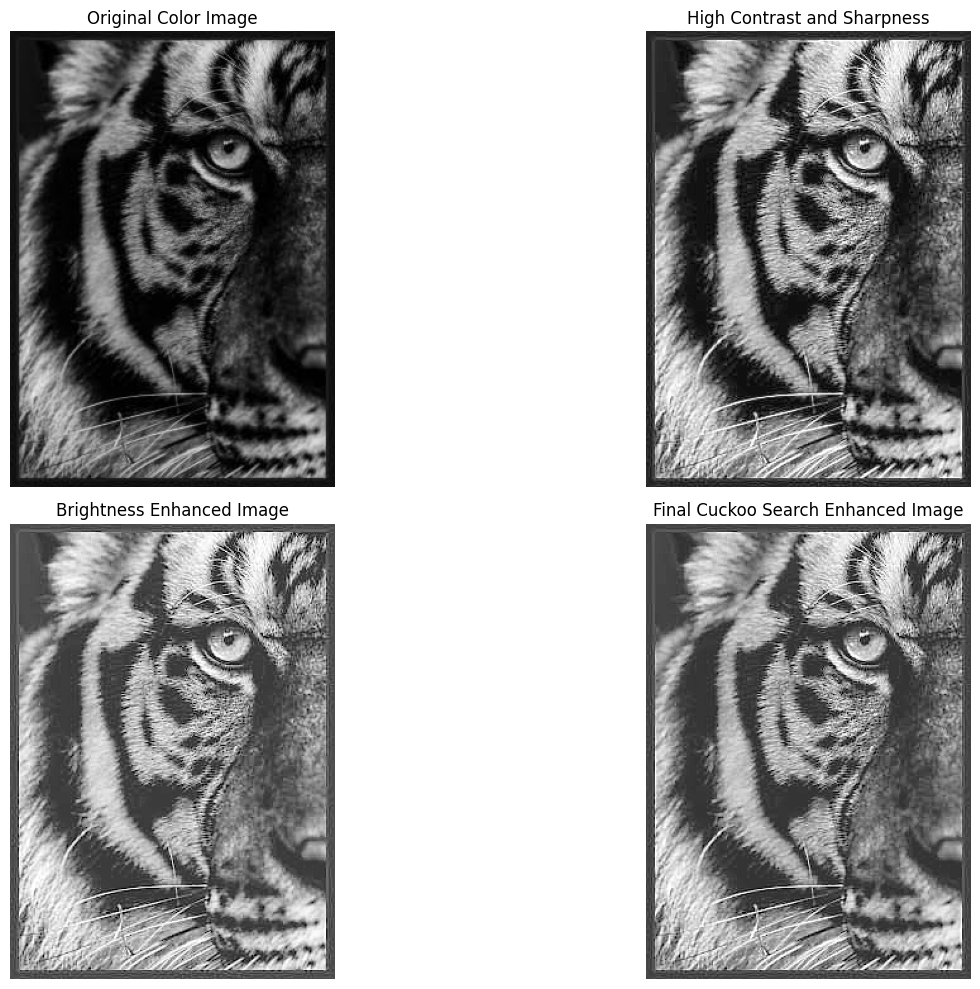

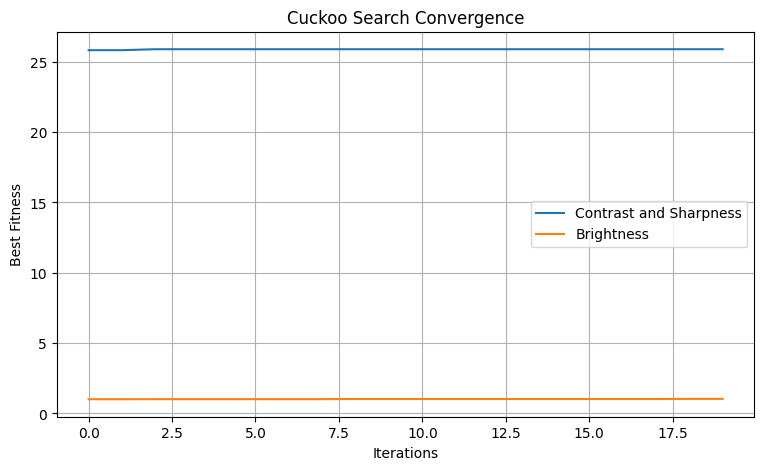


========== IMAGE ENHANCEMENT RESULTS ==========
Contrast Improvement Index: 1.0142
Brightness Improvement:     0.2390
Image Sharpness:             8189.6976
Image Entropy:               7.6436

Best Parameters - Fitness 1: [0.98985722 0.80735644 1.68503501 0.15893513]
Best Parameters - Fitness 2: [1.14963113 0.2904142  1.89512972 0.01652036]

Final color enhanced image saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

# ============================================================
# CUCKOO SEARCH BASED COLOR IMAGE ENHANCEMENT
# Two Objectives:
# 1. High Contrast and Sharpness
# 2. Brightness Enhancement
# 3. Final Image Fusion
# ============================================================

!pip -q install opencv-python-headless scipy scikit-image matplotlib

import cv2
import math
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from scipy.ndimage import uniform_filter
from scipy.special import expit
from skimage.measure import shannon_entropy

# ============================================================
# 1. UPLOAD COLOR IMAGE
# ============================================================

print("Upload your color image:")
uploaded = files.upload()

filename = next(iter(uploaded))

img_bgr = cv2.imread(filename, cv2.IMREAD_COLOR)

if img_bgr is None:
    raise ValueError("Could not read uploaded image.")

# Convert BGR to RGB
original = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Convert RGB to LAB color space
lab = cv2.cvtColor(original, cv2.COLOR_RGB2LAB)

# Extract luminance channel
L = lab[:, :, 0].astype(np.float32) / 255.0

print("Color image uploaded successfully!")
print("Image size:", original.shape)

# ============================================================
# 2. IMAGE TRANSFORMATION
# ============================================================

def transform_image(image, params):

    a, b, c, d = params

    mean = uniform_filter(image, size=3)
    mean_sq = uniform_filter(image ** 2, size=3)

    local_std = np.sqrt(
        np.maximum(mean_sq - mean ** 2, 0)
    )

    enhanced = (
        c * image
        - a * mean
        + b * local_std
    )

    low = np.percentile(enhanced, 1)
    high = np.percentile(enhanced, 99)

    enhanced = (
        enhanced - low
    ) / (high - low + 1e-8)

    enhanced = np.clip(enhanced, 0, 1)

    enhanced = np.power(
        enhanced,
        0.5 + d
    )

    return np.clip(enhanced, 0, 1)


# ============================================================
# 3. CONVERT ENHANCED LUMINANCE TO COLOR IMAGE
# ============================================================

def make_color_image(enhanced_L, original_lab):

    new_lab = original_lab.copy()

    new_lab[:, :, 0] = (
        np.clip(enhanced_L, 0, 1) * 255
    ).astype(np.uint8)

    result = cv2.cvtColor(
        new_lab,
        cv2.COLOR_LAB2RGB
    )

    return result


# ============================================================
# 4. FITNESS FUNCTION 1
# HIGH CONTRAST AND SHARPNESS
# ============================================================

def fitness1(image):

    image_uint8 = (
        np.clip(image, 0, 1) * 255
    ).astype(np.uint8)

    # Sobel edge detection
    sobel_x = cv2.Sobel(
        image_uint8,
        cv2.CV_64F,
        1, 0, ksize=3
    )

    sobel_y = cv2.Sobel(
        image_uint8,
        cv2.CV_64F,
        0, 1, ksize=3
    )

    sharpness = np.mean(
        np.sqrt(sobel_x ** 2 + sobel_y ** 2)
    )

    # Canny edge detection
    edges = cv2.Canny(
        image_uint8, 100, 200
    )

    edge_count = np.sum(edges > 0)

    # Image entropy
    entropy = shannon_entropy(image_uint8)

    # Contrast
    contrast = np.std(image)

    # Combined fitness
    score = (
        np.log1p(sharpness)
        + np.log1p(edge_count)
        + entropy
        + 10 * contrast
    )

    return float(score)


# ============================================================
# 5. FITNESS FUNCTION 2
# BRIGHTNESS ENHANCEMENT
# ============================================================

def fitness2(image):

    mean_intensity = np.mean(image)

    # Target brightness
    target = 0.55

    brightness_score = 1.0 - abs(
        mean_intensity - target
    )

    # Avoid excessive brightness changes
    contrast = np.std(image)

    score = (
        brightness_score
        + 0.2 * contrast
    )

    return float(score)


# ============================================================
# 6. LEVY FLIGHT
# ============================================================

def levy_flight(beta=1.5):

    sigma = (
        math.gamma(1 + beta)
        * math.sin(math.pi * beta / 2)
        /
        (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (
        abs(v) ** (1 / beta) + 1e-8
    )


# ============================================================
# 7. CUCKOO SEARCH ALGORITHM
# ============================================================

LOWER = np.array([0.0, 0.0, 0.5, 0.0])
UPPER = np.array([1.5, 1.5, 2.5, 1.0])

NESTS = 15
ITERATIONS = 20
PA = 0.25
ALPHA = 0.01


def cuckoo_search(objective):

    population = np.random.uniform(
        LOWER,
        UPPER,
        (NESTS, 4)
    )

    scores = np.array([
        objective(
            transform_image(L, nest)
        )
        for nest in population
    ])

    best_index = np.argmax(scores)

    best_nest = population[best_index].copy()
    best_score = scores[best_index]

    history = []

    for iteration in range(ITERATIONS):

        # Levy flight generation
        for i in range(NESTS):

            step = np.array([
                levy_flight()
                for _ in range(4)
            ])

            new_nest = (
                population[i]
                + ALPHA * step
                * (population[i] - best_nest)
            )

            new_nest = np.clip(
                new_nest, LOWER, UPPER
            )

            new_score = objective(
                transform_image(L, new_nest)
            )

            if new_score > scores[i]:

                population[i] = new_nest
                scores[i] = new_score

            if new_score > best_score:

                best_score = new_score
                best_nest = new_nest.copy()

        # Abandon nests
        abandon = np.random.rand(NESTS) < PA

        for i in range(NESTS):

            if abandon[i]:

                new_nest = np.random.uniform(
                    LOWER, UPPER, 4
                )

                new_score = objective(
                    transform_image(L, new_nest)
                )

                if new_score > scores[i]:

                    population[i] = new_nest
                    scores[i] = new_score

                if new_score > best_score:

                    best_score = new_score
                    best_nest = new_nest.copy()

        history.append(best_score)

        print(
            f"Iteration {iteration + 1}/{ITERATIONS}"
            f" | Best Fitness = {best_score:.4f}"
        )

    return best_nest, history


# ============================================================
# 8. OPTIMIZE BOTH OBJECTIVES
# ============================================================

print("\nOptimizing High Contrast and Sharpness...")

best_params1, history1 = cuckoo_search(fitness1)

print("\nOptimizing Brightness...")

best_params2, history2 = cuckoo_search(fitness2)


# ============================================================
# 9. GENERATE TWO ENHANCED IMAGES
# ============================================================

enhanced_L1 = transform_image(L, best_params1)

enhanced_L2 = transform_image(L, best_params2)

# Convert to RGB
image1 = make_color_image(
    enhanced_L1, lab
)

image2 = make_color_image(
    enhanced_L2, lab
)


# ============================================================
# 10. IMAGE FUSION
# ============================================================

A = (enhanced_L1 + enhanced_L2) / 2.0

W = expit(5 * (A - 0.5))

final_L = (
    W * enhanced_L1
    + (1 - W) * enhanced_L2
)

final_L = np.clip(final_L, 0, 1)

final_image = make_color_image(
    final_L, lab
)


# ============================================================
# 11. IMAGE QUALITY METRICS
# ============================================================

def calculate_metrics(original_L, enhanced_L):

    original_mean = np.mean(original_L)
    enhanced_mean = np.mean(enhanced_L)

    original_contrast = np.std(original_L)
    enhanced_contrast = np.std(enhanced_L)

    CII = enhanced_contrast / (
        original_contrast + 1e-8
    )

    BI = abs(
        enhanced_mean - original_mean
    )

    enhanced_uint8 = (
        enhanced_L * 255
    ).astype(np.uint8)

    sharpness = cv2.Laplacian(
        enhanced_uint8,
        cv2.CV_64F
    ).var()

    entropy = shannon_entropy(
        enhanced_uint8
    )

    return CII, BI, sharpness, entropy


cii, bi, sharpness, entropy = calculate_metrics(
    L, final_L
)


# ============================================================
# 12. DISPLAY ALL FOUR COLOR IMAGES
# ============================================================

plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.imshow(original)
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(image1)
plt.title("High Contrast and Sharpness")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(image2)
plt.title("Brightness Enhanced Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(final_image)
plt.title("Final Cuckoo Search Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 13. CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    history1,
    label="Contrast and Sharpness"
)

plt.plot(
    history2,
    label="Brightness"
)

plt.xlabel("Iterations")
plt.ylabel("Best Fitness")

plt.title("Cuckoo Search Convergence")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 14. PRINT RESULTS
# ============================================================

print("\n========== IMAGE ENHANCEMENT RESULTS ==========")

print(f"Contrast Improvement Index: {cii:.4f}")
print(f"Brightness Improvement:     {bi:.4f}")
print(f"Image Sharpness:             {sharpness:.4f}")
print(f"Image Entropy:               {entropy:.4f}")

print("\nBest Parameters - Fitness 1:", best_params1)
print("Best Parameters - Fitness 2:", best_params2)


# ============================================================
# 15. SAVE AND DOWNLOAD FINAL COLOR IMAGE
# ============================================================

output = cv2.cvtColor(
    final_image,
    cv2.COLOR_RGB2BGR
)

cv2.imwrite(
    "cuckoo_search_enhanced_color.png",
    output
)

print("\nFinal color enhanced image saved successfully!")

files.download(
    "cuckoo_search_enhanced_color.png"
)


Upload your color image:


Saving 3.jpg to 3 (1).jpg
Color image uploaded successfully!
Image size: (360, 257, 3)

Optimizing High Contrast and Sharpness...
Iteration 1/20 | Best Fitness = 25.8071
Iteration 2/20 | Best Fitness = 25.8477
Iteration 3/20 | Best Fitness = 25.8477
Iteration 4/20 | Best Fitness = 25.8477
Iteration 5/20 | Best Fitness = 25.8477
Iteration 6/20 | Best Fitness = 25.8477
Iteration 7/20 | Best Fitness = 25.8477
Iteration 8/20 | Best Fitness = 25.8477
Iteration 9/20 | Best Fitness = 25.8560
Iteration 10/20 | Best Fitness = 25.8560
Iteration 11/20 | Best Fitness = 25.8560
Iteration 12/20 | Best Fitness = 25.8560
Iteration 13/20 | Best Fitness = 25.8560
Iteration 14/20 | Best Fitness = 25.8560
Iteration 15/20 | Best Fitness = 25.8560
Iteration 16/20 | Best Fitness = 25.8560
Iteration 17/20 | Best Fitness = 25.9128
Iteration 18/20 | Best Fitness = 25.9128
Iteration 19/20 | Best Fitness = 25.9128
Iteration 20/20 | Best Fitness = 25.9128

Optimizing Brightness...
Iteration 1/20 | Best Fitness = 1

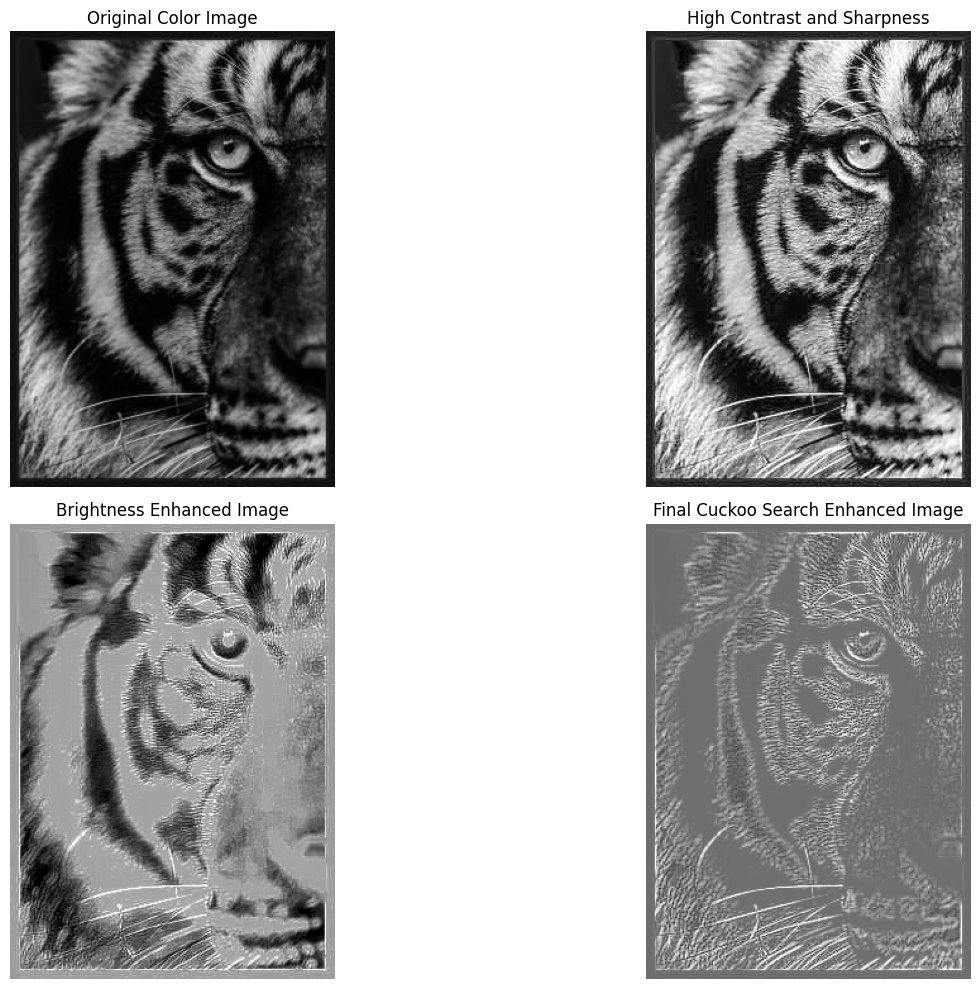


========== IMAGE ENHANCEMENT RESULTS ==========
Contrast Improvement Index: 0.4755
Brightness Improvement:     0.2574
Image Sharpness:             6217.8600
Image Entropy:               6.2082

Best Parameters - Fitness 1: [1.06113616 0.94759145 2.12913682 0.19253171]
Best Parameters - Fitness 2: [0.97777822 0.75884799 0.68975272 0.39803031]

Final color enhanced image saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

# ============================================================
# CUCKOO SEARCH BASED COLOR IMAGE ENHANCEMENT
# 1. High Contrast and Sharpness
# 2. Brightness Enhancement
# 3. Final Image Fusion
# ============================================================

!pip -q install opencv-python-headless scipy scikit-image matplotlib

import cv2
import math
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from scipy.ndimage import uniform_filter
from scipy.special import expit
from skimage.measure import shannon_entropy

# ============================================================
# 1. UPLOAD COLOR IMAGE
# ============================================================

print("Upload your color image:")
uploaded = files.upload()

filename = next(iter(uploaded))

img_bgr = cv2.imread(filename, cv2.IMREAD_COLOR)

if img_bgr is None:
    raise ValueError("Could not read uploaded image.")

original = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

lab = cv2.cvtColor(original, cv2.COLOR_RGB2LAB)

L = lab[:, :, 0].astype(np.float32) / 255.0

print("Color image uploaded successfully!")
print("Image size:", original.shape)


# ============================================================
# 2. IMAGE TRANSFORMATION
# ============================================================

def transform_image(image, params):

    a, b, c, d = params

    mean = uniform_filter(image, size=3)
    mean_sq = uniform_filter(image ** 2, size=3)

    local_std = np.sqrt(
        np.maximum(mean_sq - mean ** 2, 0)
    )

    enhanced = (
        c * image
        - a * mean
        + b * local_std
    )

    low = np.percentile(enhanced, 1)
    high = np.percentile(enhanced, 99)

    enhanced = (
        enhanced - low
    ) / (high - low + 1e-8)

    enhanced = np.clip(enhanced, 0, 1)

    enhanced = np.power(enhanced, 0.5 + d)

    return np.clip(enhanced, 0, 1)


# ============================================================
# 3. CONVERT ENHANCED LUMINANCE TO COLOR IMAGE
# ============================================================

def make_color_image(enhanced_L, original_lab):

    new_lab = original_lab.copy()

    new_lab[:, :, 0] = (
        np.clip(enhanced_L, 0, 1) * 255
    ).astype(np.uint8)

    result = cv2.cvtColor(
        new_lab,
        cv2.COLOR_LAB2RGB
    )

    return result


# ============================================================
# 4. FITNESS FUNCTION 1
# HIGH CONTRAST AND SHARPNESS
# ============================================================

def fitness1(image):

    image_uint8 = (
        np.clip(image, 0, 1) * 255
    ).astype(np.uint8)

    sobel_x = cv2.Sobel(
        image_uint8,
        cv2.CV_64F,
        1, 0, ksize=3
    )

    sobel_y = cv2.Sobel(
        image_uint8,
        cv2.CV_64F,
        0, 1, ksize=3
    )

    sharpness = np.mean(
        np.sqrt(sobel_x ** 2 + sobel_y ** 2)
    )

    edges = cv2.Canny(
        image_uint8, 100, 200
    )

    edge_count = np.sum(edges > 0)

    entropy = shannon_entropy(image_uint8)

    contrast = np.std(image)

    score = (
        np.log1p(sharpness)
        + np.log1p(edge_count)
        + entropy
        + 10 * contrast
    )

    return float(score)


# ============================================================
# 5. FITNESS FUNCTION 2
# BRIGHTNESS ENHANCEMENT
# ============================================================

def fitness2(image):

    mean_intensity = np.mean(image)

    target = 0.55

    brightness_score = 1.0 - abs(
        mean_intensity - target
    )

    contrast = np.std(image)

    score = (
        brightness_score
        + 0.2 * contrast
    )

    return float(score)


# ============================================================
# 6. LEVY FLIGHT
# ============================================================

def levy_flight(beta=1.5):

    sigma = (
        math.gamma(1 + beta)
        * math.sin(math.pi * beta / 2)
        /
        (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (
        abs(v) ** (1 / beta) + 1e-8
    )


# ============================================================
# 7. CUCKOO SEARCH ALGORITHM
# ============================================================

LOWER = np.array([0.0, 0.0, 0.5, 0.0])
UPPER = np.array([1.5, 1.5, 2.5, 1.0])

NESTS = 15
ITERATIONS = 20
PA = 0.25
ALPHA = 0.01


def cuckoo_search(objective):

    population = np.random.uniform(
        LOWER,
        UPPER,
        (NESTS, 4)
    )

    scores = np.array([
        objective(transform_image(L, nest))
        for nest in population
    ])

    best_index = np.argmax(scores)

    best_nest = population[best_index].copy()
    best_score = scores[best_index]

    for iteration in range(ITERATIONS):

        # Generate new solutions using Levy flights
        for i in range(NESTS):

            step = np.array([
                levy_flight()
                for _ in range(4)
            ])

            new_nest = (
                population[i]
                + ALPHA * step
                * (population[i] - best_nest)
            )

            new_nest = np.clip(
                new_nest, LOWER, UPPER
            )

            new_score = objective(
                transform_image(L, new_nest)
            )

            if new_score > scores[i]:

                population[i] = new_nest
                scores[i] = new_score

            if new_score > best_score:

                best_score = new_score
                best_nest = new_nest.copy()

        # Abandon some nests
        abandon = np.random.rand(NESTS) < PA

        for i in range(NESTS):

            if abandon[i]:

                new_nest = np.random.uniform(
                    LOWER, UPPER, 4
                )

                new_score = objective(
                    transform_image(L, new_nest)
                )

                if new_score > scores[i]:

                    population[i] = new_nest
                    scores[i] = new_score

                if new_score > best_score:

                    best_score = new_score
                    best_nest = new_nest.copy()

        print(
            f"Iteration {iteration + 1}/{ITERATIONS}"
            f" | Best Fitness = {best_score:.4f}"
        )

    return best_nest


# ============================================================
# 8. OPTIMIZE BOTH OBJECTIVES
# ============================================================

print("\nOptimizing High Contrast and Sharpness...")

best_params1 = cuckoo_search(fitness1)

print("\nOptimizing Brightness...")

best_params2 = cuckoo_search(fitness2)


# ============================================================
# 9. GENERATE TWO ENHANCED IMAGES
# ============================================================

enhanced_L1 = transform_image(L, best_params1)

enhanced_L2 = transform_image(L, best_params2)

image1 = make_color_image(enhanced_L1, lab)

image2 = make_color_image(enhanced_L2, lab)


# ============================================================
# 10. IMAGE FUSION
# ============================================================

A = (enhanced_L1 + enhanced_L2) / 2.0

W = expit(5 * (A - 0.5))

final_L = (
    W * enhanced_L1
    + (1 - W) * enhanced_L2
)

final_L = np.clip(final_L, 0, 1)

final_image = make_color_image(final_L, lab)


# ============================================================
# 11. IMAGE QUALITY METRICS
# ============================================================

def calculate_metrics(original_L, enhanced_L):

    original_mean = np.mean(original_L)
    enhanced_mean = np.mean(enhanced_L)

    original_contrast = np.std(original_L)
    enhanced_contrast = np.std(enhanced_L)

    CII = enhanced_contrast / (
        original_contrast + 1e-8
    )

    BI = abs(enhanced_mean - original_mean)

    enhanced_uint8 = (
        enhanced_L * 255
    ).astype(np.uint8)

    sharpness = cv2.Laplacian(
        enhanced_uint8,
        cv2.CV_64F
    ).var()

    entropy = shannon_entropy(enhanced_uint8)

    return CII, BI, sharpness, entropy


cii, bi, sharpness, entropy = calculate_metrics(
    L, final_L
)


# ============================================================
# 12. DISPLAY ALL FOUR COLOR IMAGES
# ============================================================

plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.imshow(original)
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(image1)
plt.title("High Contrast and Sharpness")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(image2)
plt.title("Brightness Enhanced Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(final_image)
plt.title("Final Cuckoo Search Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 13. PRINT IMAGE QUALITY RESULTS
# ============================================================

print("\n========== IMAGE ENHANCEMENT RESULTS ==========")

print(f"Contrast Improvement Index: {cii:.4f}")
print(f"Brightness Improvement:     {bi:.4f}")
print(f"Image Sharpness:             {sharpness:.4f}")
print(f"Image Entropy:               {entropy:.4f}")

print("\nBest Parameters - Fitness 1:", best_params1)
print("Best Parameters - Fitness 2:", best_params2)


# ============================================================
# 14. SAVE AND DOWNLOAD FINAL COLOR IMAGE
# ============================================================

output = cv2.cvtColor(
    final_image,
    cv2.COLOR_RGB2BGR
)

cv2.imwrite(
    "cuckoo_search_enhanced_color.png",
    output
)

print("\nFinal color enhanced image saved successfully!")

files.download(
    "cuckoo_search_enhanced_color.png"
)


Upload your color image:


Saving 3.jpg to 3 (2).jpg
Image uploaded successfully!
Image dimensions: (360, 257, 3)

Optimizing Contrast and Sharpness...
Iteration 1/20 | Best Fitness = 0.60108
Iteration 2/20 | Best Fitness = 0.60108
Iteration 3/20 | Best Fitness = 0.60108
Iteration 4/20 | Best Fitness = 0.60108
Iteration 5/20 | Best Fitness = 0.60108
Iteration 6/20 | Best Fitness = 0.60108
Iteration 7/20 | Best Fitness = 0.60108
Iteration 8/20 | Best Fitness = 0.60108
Iteration 9/20 | Best Fitness = 0.60108
Iteration 10/20 | Best Fitness = 0.60108
Iteration 11/20 | Best Fitness = 0.60108
Iteration 12/20 | Best Fitness = 0.60108
Iteration 13/20 | Best Fitness = 0.60108
Iteration 14/20 | Best Fitness = 0.60236
Iteration 15/20 | Best Fitness = 0.60236
Iteration 16/20 | Best Fitness = 0.60236
Iteration 17/20 | Best Fitness = 0.60236
Iteration 18/20 | Best Fitness = 0.60236
Iteration 19/20 | Best Fitness = 0.60617
Iteration 20/20 | Best Fitness = 0.60617

Optimizing Brightness...
Iteration 1/20 | Best Fitness = 1.0400

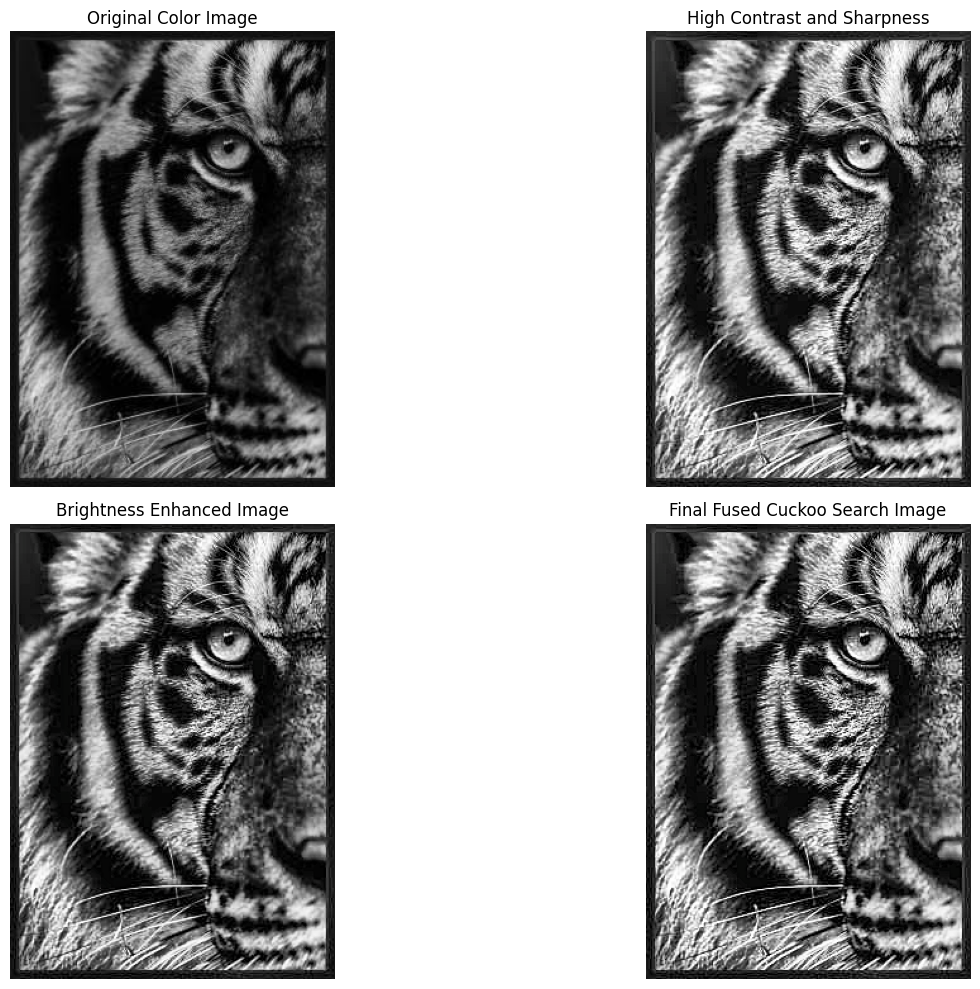


========== IMAGE ENHANCEMENT RESULTS ==========
Contrast Improvement Index: 1.3375
Brightness Improvement:     0.1308
Image Sharpness:             11575.4185
Image Entropy:               7.7191

Best Parameters - Contrast and Sharpness:
[2.47485217 0.89325977 0.64211225 0.99861895]

Best Parameters - Brightness:
[2.88596557 1.05518803 0.66797903 0.85517575]

Final enhanced color image saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

# ============================================================
# CUCKOO SEARCH BASED COLOR IMAGE ENHANCEMENT AND FUSION
#
# 1. Original Color Image
# 2. High Contrast and Sharpness Enhancement
# 3. Brightness Enhancement
# 4. Final Fused Enhanced Image
#
# Optimization: Cuckoo Search Algorithm
# Search Strategy: Levy Flight
# ============================================================

!pip -q install opencv-python-headless scipy scikit-image matplotlib

import cv2
import math
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from scipy.special import expit
from skimage.measure import shannon_entropy

np.random.seed(42)

# ============================================================
# 1. UPLOAD COLOR IMAGE
# ============================================================

print("Upload your color image:")

uploaded = files.upload()
filename = next(iter(uploaded))

img_bgr = cv2.imread(filename, cv2.IMREAD_COLOR)

if img_bgr is None:
    raise ValueError("Unable to read image.")

original = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Convert to LAB color space
lab = cv2.cvtColor(original, cv2.COLOR_RGB2LAB)

# Extract luminance
L = lab[:, :, 0].astype(np.float32) / 255.0

print("Image uploaded successfully!")
print("Image dimensions:", original.shape)


# ============================================================
# 2. IMAGE ENHANCEMENT FUNCTION
# ============================================================

def enhance_image(image, params):

    clip_limit, gamma, sharpness, blend = params

    image_uint8 = np.clip(
        image * 255, 0, 255
    ).astype(np.uint8)

    # CLAHE for local contrast enhancement
    clahe = cv2.createCLAHE(
        clipLimit=float(clip_limit),
        tileGridSize=(8, 8)
    )

    contrast_image = (
        clahe.apply(image_uint8).astype(np.float32) / 255.0
    )

    # Blend original and contrast enhanced image
    enhanced = (
        blend * contrast_image
        + (1 - blend) * image
    )

    # Gamma correction
    enhanced = np.power(
        np.clip(enhanced, 0, 1),
        gamma
    )

    # Unsharp masking for detail enhancement
    blurred = cv2.GaussianBlur(
        enhanced, (0, 0), 1.0
    )

    detail = enhanced - blurred

    enhanced = enhanced + sharpness * detail

    return np.clip(enhanced, 0, 1)


# ============================================================
# 3. FITNESS FUNCTION 1
# HIGH CONTRAST AND SHARPNESS
# ============================================================

def fitness1(image):

    img = np.clip(
        image * 255, 0, 255
    ).astype(np.uint8)

    # Contrast
    contrast = np.std(image)

    # Sobel gradient sharpness
    gx = cv2.Sobel(
        img, cv2.CV_32F, 1, 0, ksize=3
    )

    gy = cv2.Sobel(
        img, cv2.CV_32F, 0, 1, ksize=3
    )

    gradient = np.mean(
        np.sqrt(gx**2 + gy**2)
    ) / 255.0

    # Image entropy
    entropy = shannon_entropy(img) / 8.0

    # Penalize excessive black and white clipping
    clipping = np.mean(
        (img < 3) | (img > 252)
    )

    score = (
        0.40 * contrast
        + 0.35 * gradient
        + 0.25 * entropy
        - 0.20 * clipping
    )

    return float(score)


# ============================================================
# 4. FITNESS FUNCTION 2
# BRIGHTNESS ENHANCEMENT
# ============================================================

target_brightness = np.clip(
    np.mean(L) + 0.10,
    0.35,
    0.60
)


def fitness2(image):

    mean_intensity = np.mean(image)

    contrast = np.std(image)

    # Maintain natural brightness
    brightness_score = 1.0 - abs(
        mean_intensity - target_brightness
    )

    score = (
        brightness_score
        + 0.15 * contrast
    )

    return float(score)


# ============================================================
# 5. LEVY FLIGHT
# ============================================================

def levy_flight(beta=1.5):

    sigma = (
        math.gamma(1 + beta)
        * math.sin(math.pi * beta / 2)
        /
        (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / (
        abs(v) ** (1 / beta) + 1e-8
    )


# ============================================================
# 6. CUCKOO SEARCH PARAMETERS
# ============================================================

# Parameters:
# 1. CLAHE clip limit
# 2. Gamma correction
# 3. Sharpness amount
# 4. Enhancement blending factor

LOWER = np.array([
    1.0, 0.75, 0.0, 0.50
])

UPPER = np.array([
    3.0, 1.25, 0.8, 1.00
])

NESTS = 15
ITERATIONS = 20

PA = 0.25
ALPHA = 0.01


# ============================================================
# 7. CUCKOO SEARCH ALGORITHM
# ============================================================

def cuckoo_search(objective):

    population = np.random.uniform(
        LOWER,
        UPPER,
        (NESTS, 4)
    )

    scores = np.array([
        objective(enhance_image(L, nest))
        for nest in population
    ])

    best_index = np.argmax(scores)

    best_nest = population[best_index].copy()
    best_score = scores[best_index]

    for iteration in range(ITERATIONS):

        # Levy flight search
        for i in range(NESTS):

            step = np.array([
                levy_flight()
                for _ in range(4)
            ])

            new_nest = (
                population[i]
                + ALPHA * step
                * (population[i] - best_nest)
            )

            new_nest = np.clip(
                new_nest, LOWER, UPPER
            )

            new_score = objective(
                enhance_image(L, new_nest)
            )

            if new_score > scores[i]:

                population[i] = new_nest
                scores[i] = new_score

            if new_score > best_score:

                best_score = new_score
                best_nest = new_nest.copy()

        # Abandon nests
        abandon = np.random.rand(NESTS) < PA

        for i in range(NESTS):

            if abandon[i]:

                new_nest = np.random.uniform(
                    LOWER, UPPER, 4
                )

                new_score = objective(
                    enhance_image(L, new_nest)
                )

                if new_score > scores[i]:

                    population[i] = new_nest
                    scores[i] = new_score

                if new_score > best_score:

                    best_score = new_score
                    best_nest = new_nest.copy()

        print(
            f"Iteration {iteration + 1}/{ITERATIONS}"
            f" | Best Fitness = {best_score:.5f}"
        )

    return best_nest


# ============================================================
# 8. OPTIMIZE BOTH IMAGE ENHANCEMENT OBJECTIVES
# ============================================================

print("\nOptimizing Contrast and Sharpness...")

best_params1 = cuckoo_search(fitness1)

print("\nOptimizing Brightness...")

best_params2 = cuckoo_search(fitness2)


# ============================================================
# 9. GENERATE ENHANCED IMAGES
# ============================================================

enhanced_L1 = enhance_image(
    L, best_params1
)

enhanced_L2 = enhance_image(
    L, best_params2
)


# ============================================================
# 10. IMAGE FUSION
# ============================================================

# Use both enhanced images as fusion inputs
# Give more weight to the sharpness-enhanced image

fused = (
    0.65 * enhanced_L1
    + 0.35 * enhanced_L2
)

# Preserve fine image details
blurred_fusion = cv2.GaussianBlur(
    fused, (0, 0), 1.0
)

detail = fused - blurred_fusion

final_L = fused + 0.35 * detail

final_L = np.clip(final_L, 0, 1)


# ============================================================
# 11. CONVERT LAB BACK TO COLOR RGB
# ============================================================

def make_color_image(enhanced_L):

    new_lab = lab.copy()

    new_lab[:, :, 0] = (
        enhanced_L * 255
    ).astype(np.uint8)

    return cv2.cvtColor(
        new_lab,
        cv2.COLOR_LAB2RGB
    )


image1 = make_color_image(enhanced_L1)

image2 = make_color_image(enhanced_L2)

final_image = make_color_image(final_L)


# ============================================================
# 12. IMAGE QUALITY METRICS
# ============================================================

def calculate_metrics(original_L, enhanced_L):

    original_mean = np.mean(original_L)
    enhanced_mean = np.mean(enhanced_L)

    original_contrast = np.std(original_L)
    enhanced_contrast = np.std(enhanced_L)

    CII = enhanced_contrast / (
        original_contrast + 1e-8
    )

    BI = abs(
        enhanced_mean - original_mean
    )

    enhanced_uint8 = (
        enhanced_L * 255
    ).astype(np.uint8)

    sharpness = cv2.Laplacian(
        enhanced_uint8,
        cv2.CV_64F
    ).var()

    entropy = shannon_entropy(
        enhanced_uint8
    )

    return CII, BI, sharpness, entropy


cii, bi, sharpness, entropy = calculate_metrics(
    L, final_L
)


# ============================================================
# 13. DISPLAY FOUR COLOR IMAGES
# ============================================================

plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.imshow(original)
plt.title("Original Color Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(image1)
plt.title("High Contrast and Sharpness")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(image2)
plt.title("Brightness Enhanced Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(final_image)
plt.title("Final Fused Cuckoo Search Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 14. PRINT IMAGE QUALITY RESULTS
# ============================================================

print("\n========== IMAGE ENHANCEMENT RESULTS ==========")

print(f"Contrast Improvement Index: {cii:.4f}")
print(f"Brightness Improvement:     {bi:.4f}")
print(f"Image Sharpness:             {sharpness:.4f}")
print(f"Image Entropy:               {entropy:.4f}")

print("\nBest Parameters - Contrast and Sharpness:")
print(best_params1)

print("\nBest Parameters - Brightness:")
print(best_params2)


# ============================================================
# 15. SAVE AND DOWNLOAD FINAL IMAGE
# ============================================================

output = cv2.cvtColor(
    final_image,
    cv2.COLOR_RGB2BGR
)

cv2.imwrite(
    "final_cuckoo_search_enhanced.png",
    output
)

print("\nFinal enhanced color image saved successfully!")

files.download(
    "final_cuckoo_search_enhanced.png"
)
